### Laboratorium 4, część 1: Detekcja obiektów metodami klasycznymi

#### _Fabuła_
_Aby nauczyć głęboki model do segmentacji_ amodalnej _(tj. odpornej na okluzje między obiektami) konieczne jest skonstruowanie odpowiednio anotowanego zbioru uczącego.
Pozyskanie takich danych w drodze manualnej anotacji jest zbyt kosztowne, dlatego obieramy podejście oparte o generowanie danych syntetycznych.
Dane generowane będą na podstawie zbioru_ modalnego, _tj. zawierającego wyłącznie nieprzysłonięte obiekty.
Obiekty te należy najpierw wysegmentować ze specjalnie przygotowanych obrazów źródłowych, a następnie przeanalizować ich kształty -- ten właśnie krok będzie Twoim zadaniem._

#### Zadania

Twoim celem jest wykonanie detekcji i segmentacji _obiektów zainteresowania_ z podanych obrazów źródłowych.

W **pierwszej kolejności** przygotujesz potok przetwarzania przyjmujący obraz kolorowy w przestrzeni BGR/RGB a zwracający kolekcję obiektów opisanych (1) prostokątem otaczającym (_bounding box_) - na potrzeby detekcji, oraz (2) maską binarną **lub** konturem (tj. zbiorem koordynat punktów brzegowych).
Potok przetwarzania powinien obejmować binaryzację obrazu kolorowego (znanymi Ci już metodami), detekcję komponentów spójności ([`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0)), oraz analizę blobów binarnych (obiektów).
Wykryte obiekty należy przefiltrować tak, aby pozostawić wyłącznie _obiekty zainteresowania_, tj. pojedyncze larwy.
Należy więc usunąć:
* drobne obiekty niebędące larwami,
* instancje złączone,
* wszelkie inne zakłócenia.

Zaimplementuj również funkcję pozwalającą na zaprezentowanie wyników detekcji w formie rysowania prostokątów odpowiadających instancjom oraz segmentacji w formie zaznaczania pikseli należących do instancji (może być w jednej funkcji z opcją wyboru).

**Następnie** opracujesz moduł przetwarzania poszczególnych instancji na poziomie masek binarnych lub konturów.
Moduł ten ma przyjmować pojedynczą instancję i wyznaczać dla niej podstawowe informacje, takie jak:
* długość (skorzystaj z [`skimage.morphology.skeletonize`](https://scikit-image.org/docs/stable/api/skimage.morphology.html#skimage.morphology.skeletonize)) - relatywnie łatwa do _estymacji_, ale dość trudna do precyzyjnego _pomiaru_,
* grubość - może stanowić wyzwanie,
* klasyfikację kształtu (I-kształtne, S-kształtne, C-kształtne) -- potencjalnie trudne zadanie,
* ...

Nie musisz implementować ich wszystkich: na maksymalną ocenę wystarczą dwie miary zrobione _nieźle_ lub jedna opracowana _solidnie_.

#### Oczekiwane rezultaty
1. Zaprojektowanie potoku przetwarzania do detekcji i segmentacji - skonstruuj go najlepiej jako pojedynczą funkcję, ale pozostaw ślad z dokonywanych po drodze eksperymentów, tak aby możliwe było przeanalizowanie przebiegu operacji krok po kroku.
2. Zadbaj o możliwość przetworzenia tylko wybranego RoI z obrazu, aby można było przyjrzeć się "z bliska" wybranym rejonom (np. trudniejszym) -- rekomenduję zacząć pracę od wybrania mniejszego, wygodniejszego w przetwarzaniu rejonu.
3. Działanie modułu analizy zademonstruj na kilku wybranych przykładach, także umożliwiając podgląd operacji krok po kroku.
4. Debugging - jeśli na którymkolwiek etapie pojawią się problemy, których nie potrafisz rozwiązać, postaraj się przynajmniej przeanalizować, co je powoduje.

#### Literatura
1. [`cv2.findContours`](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html#gadf1ad6a0b82947fa1fe3c3d497f260e0), [OpenCV Structural Analysis and Shape Descriptors](https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html), [OpenCV Drawing Functions](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html)
2. Publikacja, której częścią był potok przetwarzania podobny do tego, który zaimplementujesz: https://ieeexplore.ieee.org/document/10924163

In [ ]:
from typing import List

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact, fixed
import random
from skimage.morphology import reconstruction
import csv, json
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.ndimage import uniform_filter1d
import skimage.morphology as skm

In [ ]:
# staraj się projektować potok przetwarzania na jednym obrazie, a następnie przetestować go na drugim
calib = cv2.imread('Lab4_dane/proc_20221213112112426_image0.jpg')
test = cv2.imread('Lab4_dane/proc_20221213112219030_image0.jpg')

In [ ]:
f, (a1, a2) = plt.subplots(1,2,figsize=(16,12))
a1.imshow(calib[...,::-1].transpose((1,0,2)))
a2.imshow(test[...,::-1].transpose((1,0,2)))

In [ ]:
def analyze_hsv(image_bgr, show_original=True, bins_h=180, bins_sv=256,
                save_dir=None):
    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)

    def save_img(name, img):
        if save_dir is not None:
            cv2.imwrite(os.path.join(save_dir, f"{name}.png"), img)

    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)

    save_img("01_original", image_bgr)
    save_img("02_channel_S", s)

    if show_original:
        plt.figure(figsize=(6, 5))
        plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
        plt.title('Original image')
        plt.axis('off')
        plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(h, cmap='gray')
    axes[0].set_title('Channel H (Hue)')
    axes[1].imshow(s, cmap='gray')
    axes[1].set_title('Channel S (Saturation)')
    axes[2].imshow(v, cmap='gray')
    axes[2].set_title('Channel V (Value)')
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    if save_dir is not None:
        fig.savefig(os.path.join(save_dir, f"02_channels_figure.png"), dpi=150)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].hist(h.flatten(), bins=bins_h, color='red', range=(0, 180))
    axes[0].set_title('Histogram H (Hue)')
    axes[1].hist(s.flatten(), bins=bins_sv, color='green', range=(0, 255))
    axes[1].set_title('Histogram S (Saturation)')
    axes[2].hist(v.flatten(), bins=bins_sv, color='blue', range=(0, 255))
    axes[2].set_title('Histogram V (Value)')
    for ax in axes:
        ax.set_xlabel('Pixel value')
        ax.set_ylabel('Pixel count')
        ax.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    if save_dir is not None:
        fig.savefig(os.path.join(save_dir, f"02_histograms.png"),
                    dpi=150)
    plt.show()

In [ ]:
analyze_hsv(calib, False, save_dir='out_calib')

**Kanały**
- **S:** larwy to jasne obiekty na ciemnym tle, najlepszy kanał do binaryzacji.
- **H:** słaby, zaszumiony kontrast.
- **V:** larwy ciemniejsze od tła, ale gradient oświetlenia i ciemne ramki utrudniają progowanie.

**Histogramy**
- **S:** bimodalny. Tło ma pik przy ok. 20–40, larwy tworzą małą górkę przy ok. 180–220, a między nimi jest dolina. Próg T = 90 leży w tej dolinie.
- **H** i **V:** brak wyraźnego rozdzielenia. Pik w zerze w H i S pochodzi z czarnych obszarów poza pojemnikiem, a słupek przy 255 w V to prześwietlenia.

**Wniosek:** do binaryzacji wybieramy kanał S. Artefakty (ramka, prześwietlenia) usunie filtr po polu i margines `border`.

In [ ]:
def threshold_s_view(image, t, save_dir=None):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    _, s, _ = cv2.split(hsv)

    mode = cv2.THRESH_BINARY
    _, binary = cv2.threshold(s, t, 255, mode)

    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        cv2.imwrite(os.path.join(save_dir, f"03_binary_T{t}.png"), binary)

    plt.figure(figsize=(8, 6))
    plt.imshow(binary, cmap='gray')
    plt.title(f'S binarization (T = {t})')
    plt.axis('off')
    plt.show()
    return binary

In [ ]:
binary = threshold_s_view(calib, 90, save_dir='out_calib')

**Wynik binaryzacji S (T = 90):**
- Larwy są dobrze wyodrębnione jako białe, spójne obiekty na czarnym tle.
- Widać drobny szum (pojedyncze punkty) i kilka artefaktów: duża biała plama na dole (ok. środka), małe prostokąty przy dolnej krawędzi, kreski przy górnej krawędzi i obiekty w rogach.
- Część larw jest złączona lub się dotyka (m.in. w górnej części i w prawym górnym rogu), więc nie będą pojedynczymi instancjami.

**Wniosek:** próg T = 90 działa dobrze. Szum i drobne obiekty usunie filtr po polu (`min_area`), plamę i brzegi `max_area` oraz `border`, a złączone larwy odrzuci filtr po polu lub CV grubości.

In [ ]:
def area_histogram(image, connectivity=8, bins=60, min_area=None, max_area=None, bg_max=1_000_000, border=0, save_dir=None, name="04_area_hist"):
    b = image.copy()
    if border > 0:
        b[:border, :] = 0; b[-border:, :] = 0
        b[:, :border] = 0; b[:, -border:] = 0

    n, labels, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=connectivity)
    areas = stats[1:, cv2.CC_STAT_AREA]
    areas = areas[areas < bg_max]

    edges = np.logspace(0, np.log10(areas.max() + 1), bins)

    fig, ax = plt.subplots(1, 2, figsize=(16, 5))

    ax[0].hist(areas, bins=edges, color='steelblue', edgecolor='black')
    ax[0].set_xscale('log')
    ax[0].set_xlabel('Area [px] (log)')
    ax[0].set_ylabel('Liczba blobów')
    ax[0].set_title(f'Histogram pól (n={len(areas)})')

    if min_area is not None and max_area is not None:
        ax[0].axvspan(1, min_area, color='red', alpha=0.15, label=f'szum (<{min_area})')
        ax[0].axvspan(min_area, max_area, color='green', alpha=0.15, label='larwy')
        ax[0].axvspan(max_area, areas.max() * 1.1, color='purple', alpha=0.15,
                      label=f'sklejone (>{max_area})')
        ax[0].legend()

    ax[1].plot(np.sort(areas), '.-', color='green', markersize=3)
    ax[1].set_yscale('log')
    ax[1].set_xlabel('Ranga'); ax[1].set_ylabel('Area [px] (log)')
    ax[1].set_title('Posortowane pola')
    for val, c in ((min_area, 'red'), (max_area, 'purple')):
        if val is not None:
            ax[1].axhline(val, color=c, linestyle='--')

    for a in ax:
        a.grid(True, which='both', linestyle='--', alpha=0.4)
    plt.tight_layout()
    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        fig.savefig(os.path.join(save_dir, f"{name}.png"), dpi=150)
    plt.show()

    if min_area is not None and max_area is not None:
        print(f"szum: {(areas < min_area).sum()} | "
              f"larwy: {((areas >= min_area) & (areas <= max_area)).sum()} | "
              f"sklejone: {(areas > max_area).sum()}")
    return areas

In [ ]:
areas = area_histogram(binary, border=20, min_area=1778, max_area=5012, save_dir='out_calib')

**Wynik analizy pól (n = 472 bloby):**

- **Szum (< 1778 px): 368.** Zdecydowana większość blobów. Pola od 1 do ok. 1000 px, z licznym wąskim słupkiem przy 1 px (ok. 37 pojedynczych pikseli).
- **Larwy (1778-5012 px): 88.** Wyraźny, wąski pik przy ok. 3500-4000 px, dobrze oddzielony od szumu.
- **Sklejone (> 5012 px): 16.** Mały ogon po prawej, w tym jeden outlier przy ok. 50 000 px (biała plama na dole obrazu).

**Wykres posortowanych pól:** widać gwałtowny skok (ok. ranga 365) z kilkuset do ok. 3000 px, potem długi, prawie płaski plateau (to larwy o podobnej wielkości), a na końcu stromy wzrost (sklejone obiekty). Progi (czerwona i fioletowa linia) leżą dokładnie na krawędziach tego plateau.

**Wniosek:** pole jest bardzo dobrym kryterium. Rozkład jest wyraźnie trójdzielny, a progi 1778 i 5012 trafnie wydzielają ok. 88 pojedynczych larw. Ewentualne sklejone larwy o polu zbliżonym do pojedynczych odfiltruje dopiero CV grubości.
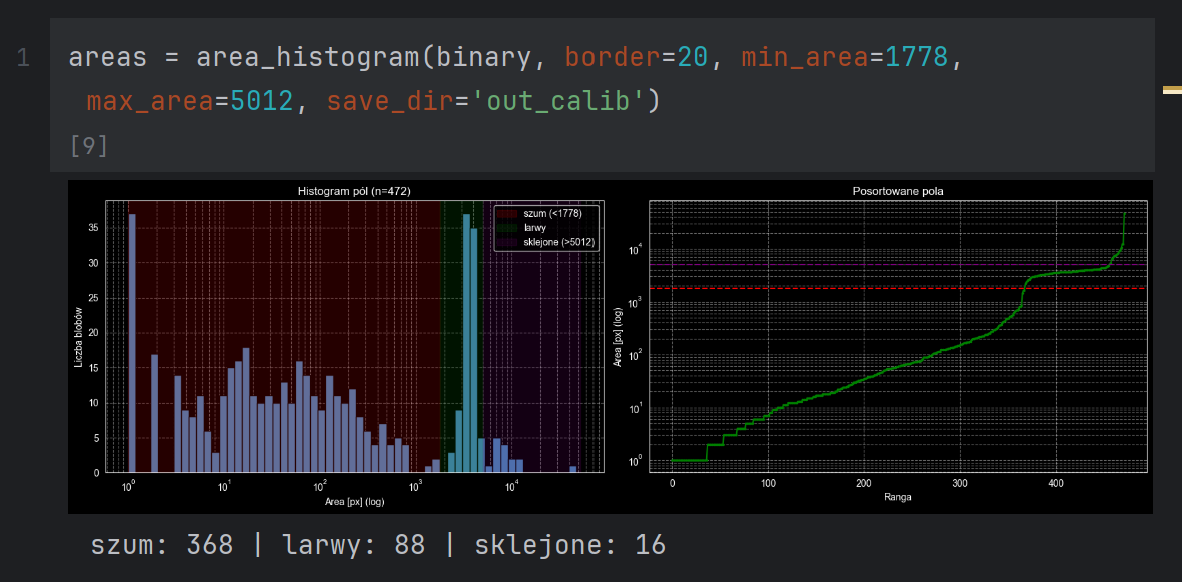

In [ ]:
def prepare_components(image, border=20, connectivity=8):
    b = image.copy()
    if border > 0:
        b[:border, :] = 0; b[-border:, :] = 0
        b[:, :border] = 0; b[:, -border:] = 0
    n, labels, stats, _ = cv2.connectedComponentsWithStats(b, connectivity=connectivity)
    return labels, stats[:, cv2.CC_STAT_AREA], stats      # areas[0] = tło; stats = x, y, w, h, area

def make_preview(image_bgr, labels, scale=0.25):
    lab = cv2.resize(labels.astype(np.int32), None, fx=scale, fy=scale,
                     interpolation=cv2.INTER_NEAREST)
    img = cv2.resize(image_bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img, lab

import csv, json

def draw_boxes(img, stats, mask_lut, color, scale=1.0, thickness=2, pad=0, label=''):
    """Rysuje prostokąty i zwraca listę informacji o nich (w układzie obrazu, na którym rysuje)."""
    H, W = img.shape[:2]
    records = []
    for i in np.where(mask_lut)[0]:
        x, y, w, h, area = stats[i]
        x0 = max(int(x * scale) - pad, 0)
        y0 = max(int(y * scale) - pad, 0)
        x1 = min(int((x + w) * scale) + pad, W - 1)
        y1 = min(int((y + h) * scale) + pad, H - 1)
        cv2.rectangle(img, (x0, y0), (x1, y1), color, thickness)
        records.append({
            'id': int(i),
            'category': label,
            'x': int(x), 'y': int(y), 'w': int(w), 'h': int(h),   # box ciasny, pełna rozdzielczość
            'x0': x0, 'y0': y0, 'x1': x1, 'y1': y1,              # box narysowany (skala + pad)
            'area': int(area),
            'aspect': round(w / h, 3) if h else None,
            'fill': round(area / (w * h), 3) if w * h else None,  # wypełnienie boxa
            'cx': int(x + w / 2), 'cy': int(y + h / 2),
        })
    return records

def save_boxes_info(records, path_csv='out_calib/05_boxes.csv', path_json='out_calib/05_boxes.json'):
    os.makedirs(os.path.dirname(path_csv) or '.', exist_ok=True)
    if records:
        with open(path_csv, 'w', newline='', encoding='utf-8') as f:
            wr = csv.DictWriter(f, fieldnames=list(records[0].keys()))
            wr.writeheader()
            wr.writerows(records)
    with open(path_json, 'w', encoding='utf-8') as f:
        json.dump(records, f, ensure_ascii=False, indent=2)
    print(f"zapisano {len(records)} boxów: {path_csv}, {path_json}")

def save_area_overlay(image_bgr, labels, areas, stats, min_area, max_area, path='out_calib/05_area_filter.png', alpha=1.0, boxes=True, save_info=True):
    too_small = areas < min_area; too_small[0] = False
    too_big   = areas > max_area; too_big[0] = False
    keep      = ~(too_small | too_big); keep[0] = False

    overlay = image_bgr.copy()
    for mask_lut, color in ((keep,      (0, 255, 0)),
                            (too_small, (0, 0, 255)),
                            (too_big,   (255, 0, 200))):
        m = mask_lut[labels]
        overlay[m] = (alpha * np.array(color) + (1 - alpha) * overlay[m]).astype(np.uint8)

    records = []
    if boxes:
        records = draw_boxes(overlay, stats, keep, (0, 255, 255),
                             scale=1.0, thickness=3, pad=4, label='keep')

    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    cv2.imwrite(path, overlay)
    if save_info and records:
        base = os.path.splitext(path)[0]
        save_boxes_info(records, base + '_boxes.csv', base + '_boxes.json')
    print(f"zapisano: {path} | za małe: {too_small.sum()} | zostają: {keep.sum()} | za duże: {too_big.sum()}")
    return overlay, records

def interactive_area_filter(img, lab, areas, stats, min_area, max_area,
                            scale=0.25, boxes=True):
    too_small = (areas < min_area); too_small[0] = False
    too_big   = (areas > max_area); too_big[0] = False
    keep      = ~(too_small | too_big); keep[0] = False

    overlay = img.copy()
    overlay[keep[lab]]      = (0, 255, 0)
    overlay[too_small[lab]] = (255, 0, 0)
    overlay[too_big[lab]]   = (200, 0, 255)

    cleaned = np.zeros_like(img)
    cleaned[keep[lab]] = img[keep[lab]]

    if boxes:
        draw_boxes(overlay, stats, keep, (255, 255, 0), scale=scale, thickness=1, pad=2)
        draw_boxes(cleaned, stats, keep, (255, 255, 0), scale=scale, thickness=1, pad=2)

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].imshow(overlay)
    ax[0].set_title(f'zielone: zostają | czerwone: < {min_area:.0f} | fioletowe: > {max_area:.0f}')
    ax[1].imshow(cleaned)
    ax[1].set_title(f'Po filtracji: {keep.sum()} obiektów '
                    f'(za małe: {too_small.sum()}, za duże: {too_big.sum()})')
    for a in ax: a.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
labels, areas, stats = prepare_components(binary, border=20)
img_small, lab_small = make_preview(calib, labels, scale=0.25)

interact(
    interactive_area_filter,
    img=fixed(img_small),
    lab=fixed(lab_small),
    areas=fixed(areas),
    stats=fixed(stats),
    scale=fixed(0.25),
    boxes=widgets.Checkbox(value=True, description='bounding boxy'),
    min_area=widgets.FloatLogSlider(value=1778, base=10, min=0, max=5, step=0.05,
                                    description='min_area:', readout_format='.0f'),
    max_area=widgets.FloatLogSlider(value=5012, base=10, min=0, max=5, step=0.05,
                                    description='max_area:', readout_format='.0f')
)
overlay_full, box_records = save_area_overlay(calib, labels, areas, stats, min_area=1778, max_area=5012)

**Wynik filtracji po polu (min_area = 1778, max_area = 5012):**

- **Zostaje 88 obiektów** (zielone, z żółtymi ramkami). To pojedyncze larwy, dobrze obrysowane.
- **Odrzucone jako za małe: 368** (czerwone). Drobny szum rozsiany po całym obrazie, m.in. narożniki.
- **Odrzucone jako za duże: 16** (fioletowe). To głównie sklejone larwy oraz duża plama na dole obrazu.
- Prawy panel pokazuje czysty wynik: same larwy na czarnym tle, bez artefaktów.
- Zapisano pliki `05_area_filter.png` oraz `05_area_filter_boxes.csv/json` z danymi boxów (to wejście dla `extract_rois`).

**Uwagi:**
- Liczby zgadzają się z histogramem (368 / 88 / 16), więc progi są spójne.
- Wśród zielonych mogą jeszcze zostać pojedyncze sklejone pary o małym polu lub wyblakłe larwy. Tym zajmą się późniejsze filtry (CV grubości i średnie S).

**Wniosek:** filtr po polu załatwia większość pracy, a wynikiem jest czysty zbiór kandydatów na pojedyncze larwy.

In [ ]:
def extract_rois(image_bgr, labels, records, s_channel=None):
    out = []
    for r in records:
        x, y, w, h = r['x'], r['y'], r['w'], r['h']
        d = {
            'id': r['id'],
            'roi': image_bgr[y:y+h, x:x+w],
            'mask': (labels[y:y+h, x:x+w] == r['id']).astype(np.uint8) * 255,
        }
        if s_channel is not None:
            d['s_roi'] = s_channel[y:y+h, x:x+w]
        out.append(d)
    return out

def local_otsu_update(rois, blur=5):
    for r in rois:
        s_roi = cv2.cvtColor(r['roi'], cv2.COLOR_BGR2HSV)[..., 1]
        if blur:
            s_roi = cv2.GaussianBlur(s_roi, (blur, blur), 0)
        t, m = cv2.threshold(s_roi, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        r['t_local'] = t
        r['mask_local'] = m
    return rois

def paste_and_show(image_bgr, rois, records, color=(0, 255, 0), alpha=0.6, box_color=(0, 255, 255), thickness=3, path='out_calib/06_local_otsu.png', figsize=(14, 10)):
    H, W = image_bgr.shape[:2]
    final = np.zeros((H, W), np.uint8)
    for r, rec in zip(rois, records):
        x, y, w, h = rec['x'], rec['y'], rec['w'], rec['h']
        final[y:y+h, x:x+w] |= r['mask_local']

    overlay = image_bgr.copy()
    m = final > 0
    overlay[m] = (alpha * np.array(color) + (1 - alpha) * overlay[m]).astype(np.uint8)
    for rec in records:
        x, y, w, h = rec['x'], rec['y'], rec['w'], rec['h']
        cv2.rectangle(overlay, (x, y), (x + w, y + h), box_color, thickness)

    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    cv2.imwrite(path, overlay)

    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f'Lokalne Otsu: {len(rois)} obiektów')
    plt.axis('off')
    plt.show()
    return final, overlay

In [ ]:
rois = extract_rois(calib, labels, box_records)
rois = local_otsu_update(rois)
final_mask, overlay_local = paste_and_show(calib, rois, box_records)

In [ ]:
def show_random_before_after(rois, k=3, seed=None):
    rng = random.Random(seed)
    chosen = rng.sample(rois, min(k, len(rois)))

    fig, ax = plt.subplots(len(chosen), 3, figsize=(12, 4 * len(chosen)))
    ax = np.atleast_2d(ax)
    for row, r in zip(ax, chosen):
        row[0].imshow(cv2.cvtColor(r['roi'], cv2.COLOR_BGR2RGB))
        row[0].set_title(f"ROI id={r['id']}")
        row[1].imshow(r['mask'], cmap='gray', vmin=0, vmax=255)
        row[1].set_title('PRZED: maska globalna (S>90)')
        row[2].imshow(r['mask_local'], cmap='gray', vmin=0, vmax=255)
        row[2].set_title(f"PO: lokalne Otsu, T={r['t_local']:.0f}")
        for a in row:
            a.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
show_random_before_after(rois, k=3)

**Wynik porównania przed/po lokalnym Otsu (3 losowe larwy):**

- **Brzegi:** po lokalnym Otsu są gładsze. Poszarpane krawędzie i drobne "ząbki" z maski globalnej (np. id=283) znikają.
- **Progi lokalne:** T = 109-113, czyli wyraźnie niższe niż globalne T = 90 w kodzie binaryzacji ma sens.
- **Kształt i rozmiar:** zasadniczo bez zmian. Maska lokalna jest minimalnie węższa, bo próg jest wyższy niż globalny.
- **Artefakt:** w id=111 pozostaje mały wyrostek z boku, to ciemna drobinka obok larwy. Lokalne Otsu go nie usuwa, bo jest połączony z larwą. Poradzi sobie z nim dopiero morfologia (erozja + dylatacja).

**Wniosek:** lokalne Otsu poprawia jakość konturu i jest lepsze od progu globalnego, ale nie rozwiązuje problemu drobnych dołączonych zanieczyszczeń. Ten krok zostawia się więc w potoku, a czyszczenie robi morfologia.

In [ ]:
def morph_update(rois, src_key='mask_local', erode_k=10, dilate_k=10, iters=1, keep_largest=True, fill=True):
    ell = lambda k: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    for r in rois:
        m = r[src_key].copy()
        if erode_k > 0:
            m = cv2.erode(m, ell(erode_k), iterations=iters)
        if dilate_k > 0:
            m = cv2.dilate(m, ell(dilate_k), iterations=iters)

        if keep_largest:                                   # zostaw największy komponent
            n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
            if n > 1:
                i = 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])
                m = ((lab == i) * 255).astype(np.uint8)
        if fill:                                           # wypełnij dziury
            cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            filled = np.zeros_like(m)
            cv2.drawContours(filled, cnts, -1, 255, -1)
            m = filled
        r['mask_morph'] = m
    return rois

def show_morph_compare(rois, before_key='mask_local', k=3, seed=None, ids=None,
                       alpha_keep=0.25, alpha_diff=0.8):
    if ids is not None:
        by_id = {r['id']: r for r in rois}
        missing = [i for i in ids if i not in by_id]
        if missing:
            print(f"brak ROI o id: {missing}")
        chosen = [by_id[i] for i in ids if i in by_id]
    else:
        chosen = random.Random(seed).sample(rois, min(k, len(rois)))

    if not chosen:
        print("Brak ROI do wyświetlenia. Dostępne id:", [r['id'] for r in rois][:30], "...")
        return

    fig, ax = plt.subplots(len(chosen), 3, figsize=(14, 4.5 * len(chosen)))
    ax = np.atleast_2d(ax)
    for row, r in zip(ax, chosen):
        rgb = cv2.cvtColor(r['roi'], cv2.COLOR_BGR2RGB)
        before, after = r[before_key] > 0, r['mask_morph'] > 0
        both, added, removed = before & after, after & ~before, before & ~after

        img_b = rgb.copy()
        cv2.drawContours(img_b, cv2.findContours(r[before_key], cv2.RETR_EXTERNAL,
                                                 cv2.CHAIN_APPROX_NONE)[0], -1, (170, 255, 170), 1)
        img_a = rgb.astype(np.float32)
        for m, col, a_ in ((both,    (170, 255, 170), alpha_keep),
                           (added,   (255, 220, 0),   alpha_diff),
                           (removed, (255, 0, 0),     alpha_diff)):
            img_a[m] = a_ * np.array(col) + (1 - a_) * img_a[m]

        rid = r['id']
        row[0].imshow(rgb, interpolation='nearest'); row[0].set_title(f"ROI id={rid}")
        row[1].imshow(img_b, interpolation='nearest'); row[1].set_title(f"id={rid} PRZED: area={before.sum()}")
        row[2].imshow(img_a.astype(np.uint8), interpolation='nearest')
        row[2].set_title(f"id={rid} PO: area={after.sum()} (+{added.sum()} żółte / -{removed.sum()} czerwone)")
        for a in row: a.axis('off')
    plt.tight_layout(); plt.show()


def paste_mask_and_show(image_bgr, rois, records, mask_key, before_key=None,
                        color=(170, 255, 170), alpha=0.25, alpha_diff=0.8,
                        box_color=(0, 255, 255), thickness=3,
                        draw_ids=True, ids=None, font_scale=1.5,
                        crop=None,                      # crop=(x0, y0, x1, y1) -> przybliżenie fragmentu
                        path=None, title='', figsize=(14, 10)):
    H, W = image_bgr.shape[:2]
    final = np.zeros((H, W), np.uint8)
    added_full = np.zeros((H, W), bool)
    removed_full = np.zeros((H, W), bool)
    used = []
    for r, rec in zip(rois, records):
        if ids is not None and r['id'] not in ids:
            continue
        used.append((r, rec))
        x, y, w, h = rec['x'], rec['y'], rec['w'], rec['h']
        final[y:y+h, x:x+w] |= r[mask_key]
        if before_key is not None:
            b, a = r[before_key] > 0, r[mask_key] > 0
            added_full[y:y+h, x:x+w] |= a & ~b
            removed_full[y:y+h, x:x+w] |= b & ~a

    overlay = image_bgr.copy()
    def tint(m, col, a_):
        overlay[m] = (a_ * np.array(col) + (1 - a_) * overlay[m]).astype(np.uint8)

    tint(final > 0, color, alpha)
    if before_key is not None:
        tint(added_full, (0, 220, 255), alpha_diff)    # żółty
        tint(removed_full, (0, 0, 255), alpha_diff)    # czerwony

    for r, rec in used:
        x, y, w, h = rec['x'], rec['y'], rec['w'], rec['h']
        cv2.rectangle(overlay, (x, y), (x + w, y + h), box_color, thickness)
        if draw_ids:
            txt, pos = str(r['id']), (x, max(y - 8, 30))
            cv2.putText(overlay, txt, pos, cv2.FONT_HERSHEY_SIMPLEX, font_scale,
                        (0, 0, 0), 6, cv2.LINE_AA)           # czarna obwódka
            cv2.putText(overlay, txt, pos, cv2.FONT_HERSHEY_SIMPLEX, font_scale,
                        (255, 255, 255), 2, cv2.LINE_AA)     # biały tekst

    if path:
        os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
        cv2.imwrite(path, overlay)

    view = overlay if crop is None else overlay[crop[1]:crop[3], crop[0]:crop[2]]
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB), interpolation='nearest')
    plt.title(title or f'{mask_key}: {len(used)} obiektów')
    plt.axis('off')
    plt.show()
    return final, overlay

In [ ]:
rois = morph_update(rois, src_key='mask_local', erode_k=5, dilate_k=5)
final_morph, overlay_morph = paste_mask_and_show(
    calib, rois, box_records, 'mask_morph', before_key='mask_local',
    path='out_calib/07_eros_dyl.png')

In [ ]:
show_morph_compare(rois, before_key='mask_local', ids=[63, 90, 95, 183, 196, 63, 226])

**Wynik morfologii (porównanie przed/po, 6 ROI):**

Legenda: czerwony = usunięte, żółty = dodane (nigdzie się nie pojawia, więc operacja tylko ujmuje piksele).

- **id=63** (4111 → 3723, -388): usunięty został oderwany fragment obok larwy (czerwona plama w lewym górnym rogu). `keep_largest` zadziałał dokładnie tak, jak miał.
- **id=90** (3379 → 3344, -35): drobne ubytki przy czubku głowy i mała "wysepka". Kształt larwy bez zmian.
- **id=95** (4196 → 4196, 0): maska bez zmian. W ROI siedzi dziwny wyrostek (zgrubienie z boku), który został w masce, bo jest połączony z ciałem i grubszy niż jądro 5 px.
- **id=183** (5565 → 3725, -1840): usunięta cała druga larwa wpadająca do prostokąta. Zostaje właściwa, długa larwa. To najlepszy przykład potrzeby `keep_largest`.
- **id=196** (4417 → 4255, -162): usunięty fragment sąsiedniego obiektu przy górnej krawędzi.
- **id=226** (3311 → 3307, -4): praktycznie bez zmian (kilka pojedynczych pikseli na brzegu).

**Wnioski:**
- Morfologia głównie **usuwa obce obiekty** z prostokąta (ROI zawiera sąsiadów), a sam kontur larwy zmienia minimalnie, więc nie psuje pomiarów długości i grubości.
- Nie usuwa wyrostków połączonych z ciałem (id=95, też zgrubienie przy ogonie w id=183). Takie larwy są podejrzane i mogą być sklejone lub zdeformowane. Dobrze, że dalej jest filtr CV grubości, który je wyłapie.
- Jądro 5 px jest bezpieczne: larwy nie tracą cienkich końców.

In [ ]:
def jaggedness_report(rois, src_key='mask_local', open_k=3, close_k=3, top=10):
    ell = lambda k: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    rows = []
    for r in rois:
        m = r[src_key]
        area = int((m > 0).sum())
        if area < 50:
            continue

        # 1) liczba dziur = komponenty tła wewnątrz larwy
        inv = cv2.bitwise_not(m)
        n_bg, _, st_bg, _ = cv2.connectedComponentsWithStats((inv > 0).astype(np.uint8), 8)
        holes = int((st_bg[1:, cv2.CC_STAT_AREA] < 0.5 * area).sum()) - 0  # bez wielkiego tła
        holes = max(holes - 1, 0)   # odejmij zewnętrzne tło, gdyby się załapało

        # 2) ile zmienia otwarcie + zamknięcie (poszarpany brzeg -> duża zmiana)
        opened = cv2.morphologyEx(m, cv2.MORPH_OPEN,  ell(open_k))
        closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, ell(close_k))
        changed = int(np.count_nonzero((m > 0) != (closed > 0)))
        change_frac = changed / area

        # 3) chropowatość brzegu: obwód^2 / pole (gładka larwa ma mało, poszarpana dużo)
        cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        per = max((cv2.arcLength(c, True) for c in cnts), default=0)
        roughness = (per * per) / area if area else 0

        rows.append({'id': r['id'], 't_local': r.get('t_local', np.nan),
                     'holes': holes, 'change_frac': round(change_frac, 3),
                     'roughness': round(roughness, 1), 'area': area})

    rows.sort(key=lambda d: -d['change_frac'])     # najwięcej zmienia morfologia = najlepszy przykład
    print(f"{'id':>5} {'t_loc':>6} {'dziur':>6} {'zmiana':>7} {'chrop.':>7} {'area':>6}")
    for d in rows[:top]:
        print(f"{d['id']:>5} {d['t_local']:>6.0f} {d['holes']:>6} "
              f"{d['change_frac']:>7.3f} {d['roughness']:>7.1f} {d['area']:>6}")
    return [d['id'] for d in rows[:top]]

In [ ]:
ids_jagged = jaggedness_report(rois, src_key='mask_local', open_k=3, close_k=3, top=10)
show_morph_compare(rois, before_key='mask_local', ids=ids_jagged[:3])

**Wynik raportu poszarpania (top 10) i podglądu 3 najgorszych:**

- **Skala zmian jest mała.** Najwyższa `zmiana` to 0,016 (id=292), reszta 0,004-0,006, czyli otwarcie + zamknięcie 3×3 zmienia poniżej 1,6% pikseli. Maski lokalnego Otsu są więc w większości gładkie.
- **id=292 (zmiana 0,016, chrop. 49,1, T=101):** wyraźnie się wyróżnia. Na lewym brzegu jest poszarpany ślad po fioletowej obwódce cienia, a morfologia usuwa wąski pasek (-63 px). To jedyny prawdziwy przypadek poszarpania. Powód: niski próg lokalny (101 wobec 106-117 u pozostałych) wciąga cień do maski.
- **id=328 (0,006):** maska bez zmian (-0 px), 2 "dziury" prawdopodobnie fałszywe (patrz uwaga niżej). Kontur gładki.
- **id=75 (0,005):** drobny wyrostek na górze (włosek/zanieczyszczenie) i kilka pikseli na końcach, w sumie -6 px. Kształt C nietknięty.
- **Chropowatość** (obwód²/pole) 36-40 dla typowych larw, a 49 dla id=292, więc ta miara potwierdza ranking `zmiana`.
- **Dziury (0-2):** larwy nie mają dziur, więc 1-2 to raczej artefakt heurystyki (komponenty tła o niewielkim polu przy brzegu ROI), a nie realne dziury. Nie opieraj na tej kolumnie żadnej decyzji.

**Wniosek:** poszarpanie nie jest realnym problemem, bo poza id=292 maski są czyste. Morfologia 5×5 z potoku ma tu niewiele do roboty. Przypadek 292 pokazuje za to słabość progu Otsu przy fioletowym cieniu, ale po `morph_update` kontur jest już poprawny.

In [ ]:
def thickness_profile(mask):
    b = (mask > 0).astype(np.uint8)
    dist = cv2.distanceTransform(b, cv2.DIST_L2, 5)
    skel = skm.skeletonize(b > 0)
    th = 2.0 * dist[skel]
    return th[th > 0]

def thickness_cv(mask, trim_low=0.0, trim_high=0.):
    th = thickness_profile(mask)
    if th.size < 5:
        return None
    th = np.sort(th)
    lo = int(len(th) * trim_low)
    hi = int(len(th) * trim_high)
    core = th[lo:len(th) - hi]
    if core.size < 3:
        core = th
    mean = core.mean()
    return float(core.std() / mean) if mean else None

def thickness_cv_histogram(rois, mask_key='mask_morph', trim=0.1, bins=40,
                           thr=0.35, save_dir=None, name='10_thickness_cv'):
    pairs = [(r['id'], thickness_cv(r[mask_key], trim)) for r in rois]
    pairs = [(i, c) for i, c in pairs if c is not None]
    if not pairs:
        print("Brak larw z policzalną grubością.")
        return [], np.array([])
    ids  = [i for i, _ in pairs]
    vals = np.array([c for _, c in pairs])

    med = float(np.median(vals))
    print(f"n={len(vals)}  min={vals.min():.3f}  mediana={med:.3f}  "
          f"max={vals.max():.3f}  >{thr}: {(vals > thr).sum()}")

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(vals, bins=bins, color='steelblue', edgecolor='black')
    ax.axvline(med, color='green', ls='-',  label=f'mediana={med:.3f}')
    ax.axvline(thr, color='red',   ls='--', label=f'próg={thr}')
    ax.set_xlabel('CV grubości (std / mean)')
    ax.set_ylabel('Liczba larw')
    ax.set_title('Rozkład zmienności grubości po ROI')
    ax.legend()
    ax.grid(True, ls='--', alpha=0.4)
    plt.tight_layout()
    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        fig.savefig(os.path.join(save_dir, f'{name}.png'), dpi=150)
    plt.show()

    worst = sorted(pairs, key=lambda t: -t[1])[:10]
    print("najwyższe CV (id, cv):", [(i, round(c, 3)) for i, c in worst])
    return ids, vals

In [ ]:
ids, vals = thickness_cv_histogram(rois, mask_key='mask_morph', thr=0.13,
                                   save_dir='out_calib')

In [ ]:
def build_cv_lut(rois, labels_max, mask_key='mask_morph', trim=0.1):
    cv_lut = np.full(labels_max + 1, np.nan, dtype=np.float32)
    for r in rois:
        c = thickness_cv(r[mask_key], trim)
        if c is not None:
            cv_lut[r['id']] = c
    return cv_lut

def interactive_cv_filter(img, lab, cv_lut, rois, thr=0.35, scale=0.25, max_show=22):
    valid = ~np.isnan(cv_lut)
    good = valid & (cv_lut <= thr)
    bad  = valid & (cv_lut >  thr)
    good[0] = bad[0] = False

    overlay = img.copy()
    overlay[good[lab]] = (0, 255, 0)
    overlay[bad[lab]]  = (255, 0, 0)

    cleaned = np.zeros_like(img)
    cleaned[good[lab]] = img[good[lab]]

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].imshow(overlay)
    ax[0].set_title(f'zielone: CV ≤ {thr:.3f} | czerwone: CV > {thr:.3f}')
    ax[1].imshow(cleaned)
    ax[1].set_title(f'Zaakceptowane: {good.sum()} | odrzucone: {bad.sum()}')
    for a in ax: a.axis('off')
    plt.tight_layout()
    plt.show()

    # --- pod spodem: wycinki odrzuconych larw (CV > próg) ---
    bad_ids = {i for i in np.where(bad)[0]}
    rejected = [r for r in rois if r['id'] in bad_ids]
    rejected.sort(key=lambda r: -cv_lut[r['id']])          # od najgorszych
    if not rejected:
        print("Brak odrzuconych przy tym progu.")
        return

    show = rejected[:max_show]
    ncol = 4
    nrow = int(np.ceil(len(show) / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(14, 3.2 * nrow))
    ax = np.atleast_2d(ax)
    for a in ax.flat:
        a.axis('off')
    for a, r in zip(ax.flat, show):
        a.imshow(cv2.cvtColor(r['roi'], cv2.COLOR_BGR2RGB))
        a.set_title(f"id={r['id']}  CV={cv_lut[r['id']]:.3f}")
    fig.suptitle(f'Odrzucone (CV > {thr:.3f}): {len(rejected)}'
                 + (f', pokazano {len(show)}' if len(rejected) > max_show else ''))
    plt.tight_layout()
    plt.show()

In [ ]:
cv_lut = build_cv_lut(rois, labels.max(), mask_key='mask_morph')
img_small, lab_small = make_preview(calib, labels, scale=0.25)

interact(
    interactive_cv_filter,
    img=fixed(img_small),
    lab=fixed(lab_small),
    cv_lut=fixed(cv_lut),
    rois=fixed(rois),
    scale=fixed(0.25),
    thr=widgets.FloatSlider(value=0.100, min=0.05, max=1.0, step=0.01,
                            description='próg CV:', readout_format='.3f'),
)

**Wynik filtru CV grubości:**

**Histogram (n = 88):**
- CV od 0,042 do 0,249, mediana 0,081.
- Większość larw (ok. 76) skupia się w przedziale 0,04-0,12, a 12 leży powyżej progu 0,13 i tworzy rzadki ogon do 0,25.
- Rozkład nie jest wyraźnie dwumodalny. Między 0,12 a 0,13 jest tylko niewielka przerwa, więc próg 0,13 jest sensowny, ale nie ma ostrej granicy.

**Interaktywny filtr (próg 0,10):**
- Zaakceptowanych 66, odrzuconych 22. Przy 0,10 odpada o 10 larw więcej niż przy 0,13.
- **Dobrze odrzucone (CV 0,14-0,25):** id=95, 161, 236, 77, 366, 196, 201, 307. To larwy ze zgrubieniami, wyrostkami, dołączonymi fragmentami lub bardzo mocno zwinięte. Nie nadają się na pojedyncze instancje.
- **Fałszywe odrzucenia (CV 0,10-0,13):** id=121, 197, 232, 259, 353, 378, 143, 79, 141 to zwykłe, poprawne larwy. Przy progu 0,10 zostałyby niepotrzebnie usunięte.
- **Przypadki graniczne:** id=34 (0,181) i id=307 (0,137) wyglądają na poprawne larwy z fioletowym cieniem, który zawyża CV. id=180 (0,120) to mocno zwinięta larwa.

**Wniosek:** próg 0,13 jest lepszym wyborem niż 0,10, bo zachowuje poprawne larwy w zakresie 0,10-0,13 i nadal odrzuca wyraźne deformacje. Uwaga: w potoku (`apply_cv_filter`, `detect_objects`) domyślnie ustawiono 0,10, więc ustaw tam 0,13, żeby było spójnie z histogramem. Pojedyncze larwy z cieniem (34, 307) będą odrzucane niezależnie od progu, ale to akceptowalna strata dla zbioru uczącego.

In [ ]:
def apply_cv_filter(image_bgr, labels, cv_lut, rois, records, thr=0.13,
                    draw_ids=True, font_scale=1.2, path=None, figsize=(14, 10)):
    valid = ~np.isnan(cv_lut)
    good = valid & (cv_lut <= thr); good[0] = False
    bad  = valid & (cv_lut >  thr); bad[0]  = False
    keep_ids = set(np.where(good)[0])
    rej_ids  = set(np.where(bad)[0])

    rois_keep     = [r for r in rois if r['id'] in keep_ids]
    rois_rejected = [r for r in rois if r['id'] in rej_ids]

    overlay = image_bgr.copy()
    a = 0.45
    for mask_lut, color in ((good, (0, 255, 0)), (bad, (0, 0, 255))):
        m = mask_lut[labels]
        overlay[m] = (a * np.array(color) + (1 - a) * overlay[m]).astype(np.uint8)

    if draw_ids:
        for rec in records:
            if rec['id'] not in keep_ids and rec['id'] not in rej_ids:
                continue
            x, y = rec['x'], rec['y']
            col = (0, 200, 0) if rec['id'] in keep_ids else (0, 0, 255)
            pos = (x, max(y - 8, 25))
            cv2.putText(overlay, str(rec['id']), pos, cv2.FONT_HERSHEY_SIMPLEX,
                        font_scale, (0, 0, 0), 5, cv2.LINE_AA)
            cv2.putText(overlay, str(rec['id']), pos, cv2.FONT_HERSHEY_SIMPLEX,
                        font_scale, (255, 255, 255), 2, cv2.LINE_AA)

    if path:
        os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
        cv2.imwrite(path, overlay)

    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f'Próg CV={thr:.3f} | zostaje: {len(rois_keep)} | odrzucono: {len(rois_rejected)}')
    plt.axis('off')
    plt.show()
    print(f"zaakceptowane: {len(rois_keep)} | odrzucone: {len(rois_rejected)}")
    return rois_keep, rois_rejected, overlay

In [ ]:
cv_lut = build_cv_lut(rois, labels.max(), mask_key='mask_morph')

rois, rois_rejected, overlay = apply_cv_filter(
    calib, labels, cv_lut, rois, box_records, thr=0.100,
    path='out_calib/11_cv_filter.png')

In [ ]:
def color_stats(roi_bgr, mask):
    m = mask > 0
    if m.sum() < 10:
        return None
    hsv = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0][m], hsv[..., 1][m], hsv[..., 2][m]
    return {'H': float(h.mean()), 'S': float(s.mean()), 'V': float(v.mean()),
            'S_med': float(np.median(s)), 'V_med': float(np.median(v))}

def build_color_table(rois, mask_key='mask_morph'):
    for r in rois:
        r['color'] = color_stats(r['roi'], r[mask_key])
    return rois

In [ ]:
build_color_table(rois)
S = np.array([r['color']['S'] for r in rois if r['color']])
V = np.array([r['color']['V'] for r in rois if r['color']])
ids = [r['id'] for r in rois if r['color']]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(S, bins=40, color='orange', edgecolor='k'); ax[0].set_title('Nasycenie S'); ax[0].set_xlabel('S')
ax[1].hist(V, bins=40, color='gray',   edgecolor='k'); ax[1].set_title('Jasność V');  ax[1].set_xlabel('V')
ax[2].scatter(S, V, s=12); ax[2].set_xlabel('S'); ax[2].set_ylabel('V'); ax[2].set_title('S vs V')
for a in ax: a.grid(True, ls='--', alpha=0.4)
plt.tight_layout(); plt.show()

# posortuj od najbardziej bladych (niskie S) - kandydaci na martwe
order = np.argsort(S)
print("najniższe S (id, S, V):", [(ids[i], round(float(S[i]),1), round(float(V[i]),1)) for i in order[:15]])

In [ ]:
# znajdź larwę o najniższym S
r_low = min((r for r in rois if r.get('color')), key=lambda r: r['color']['S'])
print("najniższe S:", r_low['id'], r_low['color'])

plt.figure(figsize=(5, 4))
plt.imshow(cv2.cvtColor(r_low['roi'], cv2.COLOR_BGR2RGB))
plt.title(f"id={r_low['id']}  S={r_low['color']['S']:.0f}  V={r_low['color']['V']:.0f}")
plt.axis('off'); plt.show()

In [ ]:
def remove_pale(image_bgr, labels, rois, records=None, s_max=140, mask_key='mask_morph',
                path=None, figsize=(14, 10)):
    removed_ids = []
    for r in rois:
        c = r.get('color') or color_stats(r['roi'], r[mask_key])
        if c and c['S'] < s_max:
            removed_ids.append(r['id'])
    removed_ids = set(removed_ids)

    rois_keep = [r for r in rois if r['id'] not in removed_ids]

    # podgląd: cała larwa na czerwono tam, gdzie usuwamy
    overlay = image_bgr.copy()
    dead_lut = np.zeros(labels.max() + 1, bool)
    for i in removed_ids:
        dead_lut[i] = True
    m = dead_lut[labels]
    overlay[m] = (0.5 * np.array((0, 0, 255)) + 0.5 * overlay[m]).astype(np.uint8)
    if records:
        for rec in records:
            if rec['id'] in removed_ids:
                x, y, w, h = rec['x'], rec['y'], rec['w'], rec['h']
                cv2.rectangle(overlay, (x, y), (x + w, y + h), (0, 0, 255), 3)

    if path:
        os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
        cv2.imwrite(path, overlay)

    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f'Usunięto martwe (S < {s_max}): {len(removed_ids)} | zostaje: {len(rois_keep)}')
    plt.axis('off'); plt.show()

    print(f"usunięte id: {sorted(removed_ids)} | zostaje {len(rois_keep)} larw")
    return rois_keep, removed_ids, overlay

In [ ]:
rois, removed_ids, overlay = remove_pale(
    calib, labels, rois, box_records, s_max=140,
    path='out_calib/12_no_dead.png')

**Wynik filtra bladych larw (s_max = 140):**

- **Najniższe S: id=226** (S ≈ 120, V ≈ 206, H ≈ 21). To jasnożółta, rozmyta larwa, wyraźnie bledsza od typowych pomarańczowych.
- **Usunięta tylko jedna larwa (id=226)**, zostaje 65. Na obrazie zaznaczona czerwoną ramką po prawej stronie, a pozostałe larwy mają typowy pomarańczowy kolor.
- Wniosek z listy: S dla pozostałych larw jest już powyżej 140, więc id=226 jest wyraźnym odstępstwem, a nie początkiem ciągłego ogona.

**Ocena trafności:**
- Larwa jest jasna i rozmyta (poza ostrością), więc może być po prostu żywą, jasną larwą, a nie martwą. Niskie S wynika też z rozmycia, które uśrednia kolor z tłem. Nie ma pewności, że to martwa larwa, ale jako przypadek odstający lepiej ją pominąć w zbiorze uczącym.
- Na pełnym obrazie widać jeszcze jedną jasną, żółtawą larwę w centrum (przy ok. x=520, y=495), która też mogła odpaść wcześniej (sklejona lub odrzucona przez CV), więc filtr S jej nie dotyczy.

**Wniosek:** próg 140 działa i usuwa jedyny wyraźny odstający obiekt. Wpływ na zbiór jest minimalny (1 z 66), więc zostaw go jako zabezpieczenie. Dla pewności możesz dopisać do filtra warunek na V lub ostrość, jeśli chcesz odróżniać larwy martwe od rozmytych.

Po całym potoku zostaje na obrazie `calib` **65 larw** (88 po polu, 66 po CV 0,10, minus 1 blada).

#### Klasyfikacja kształtu (I / C / S)
Znakowane odchylenie osi od cięciwy, znormalizowane długością
(bez różniczkowania, więc odporne na szum). Dla łuku o kącie θ: odchylenie/długość ≈ θ/8.

In [ ]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.ndimage import uniform_filter1d, gaussian_filter1d
import skimage.morphology as skm

def _skeleton_graph(skel):
    H, W = skel.shape
    ys, xs = np.nonzero(skel)
    n = len(xs)
    idx = -np.ones((H, W), np.int64)
    idx[ys, xs] = np.arange(n)
    rows, cols, wts = [], [], []
    for dy, dx in ((0, 1), (1, 0), (1, 1), (1, -1)):      # każda krawędź raz
        y2, x2 = ys + dy, xs + dx
        ok = (y2 >= 0) & (y2 < H) & (x2 >= 0) & (x2 < W)
        j = np.full(n, -1, np.int64)
        j[ok] = idx[y2[ok], x2[ok]]
        m = j >= 0
        rows.append(np.arange(n)[m]); cols.append(j[m])
        wts.append(np.full(m.sum(), np.hypot(dy, dx)))
    r, c, w = map(np.concatenate, (rows, cols, wts))
    g = coo_matrix((w, (r, c)), shape=(n, n))
    return (g + g.T).tocsr(), xs, ys

def skeleton_longest_path(mask):
    b = mask > 0
    if b.sum() < 10:
        return None, None
    skel = skm.skeletonize(b)
    if skel.sum() < 3:
        return None, skel
    g, xs, ys = _skeleton_graph(skel)
    d0 = dijkstra(g, indices=0)
    d0[~np.isfinite(d0)] = -1
    a = int(np.argmax(d0))
    da, pred = dijkstra(g, indices=a, return_predecessors=True)
    da[~np.isfinite(da)] = -1
    bb = int(np.argmax(da))
    idxs = [bb]
    while idxs[-1] != a and pred[idxs[-1]] >= 0:
        idxs.append(int(pred[idxs[-1]]))
    path = np.column_stack([xs[idxs], ys[idxs]]).astype(float)
    return path, skel

def shape_features(mask, trim_frac=0.04, smooth_win=7, sigma=8):
    path, _ = skeleton_longest_path(mask)
    if path is None or len(path) < 10:
        return None
    k = int(len(path) * trim_frac)                       # utnij widełki na końcach
    p = path[k:len(path) - k] if len(path) - 2 * k >= 10 else path

    # odchylenie od cięciwy
    ps = np.column_stack([uniform_filter1d(p[:, 0], smooth_win, mode='nearest'),
                          uniform_filter1d(p[:, 1], smooth_win, mode='nearest')])
    L = float(np.linalg.norm(np.diff(ps, axis=0), axis=1).sum())
    chord = ps[-1] - ps[0]
    cl = float(np.linalg.norm(chord))
    if L < 1e-6 or cl < 1e-6:
        return None
    nrm = np.array([-chord[1], chord[0]]) / cl
    dev = (ps - ps[0]) @ nrm                             # znakowana odległość [px]

    # kąt stycznej na osi przepróbkowanej co 1 px i mocno wygładzonej
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(p, axis=0), axis=1))]
    su = np.arange(0, s[-1], 1.0)
    x = gaussian_filter1d(np.interp(su, s, p[:, 0]), sigma, mode='nearest')
    y = gaussian_filter1d(np.interp(su, s, p[:, 1]), sigma, mode='nearest')
    m = 2 * sigma                                        # brzegi filtra niewiarygodne
    if len(su) > 2 * m + 5:
        x, y, su = x[m:-m], y[m:-m], su[m:-m]
    theta = np.unwrap(np.arctan2(np.gradient(y), np.gradient(x)))
    rise = float(np.max(theta - np.minimum.accumulate(theta)))
    fall = float(np.max(np.maximum.accumulate(theta) - theta))

    return {'dev_pos': max(dev.max(), 0) / L, 'dev_neg': max(-dev.min(), 0) / L,
            'straight': cl / L, 'rise': rise, 'fall': fall, 'length': L,
            'path': ps, 'dev': dev, 's_theta': su, 'theta': theta}

def classify_features(f, i_dev=0.10, s_ang=0.45):
    if f is None:
        return '?'
    if min(f['rise'], f['fall']) >= s_ang:
        return 'S'
    if max(f['dev_pos'], f['dev_neg']) < i_dev:
        return 'I'
    return 'C'

def classify_shape(mask, i_dev=0.085, s_ang=0.5, **feat_kw):
    return classify_features(shape_features(mask, **feat_kw), i_dev, s_ang)

def build_shape_lut(cache, i_dev=0.085, s_ang=0.5):
    return {i: classify_features(f, i_dev, s_ang) for i, f in cache.items()}

# ---------- wizualizacje ----------
SHAPE_BGR = {'I': (0, 200, 0), 'C': (0, 170, 255), 'S': (255, 80, 0), '?': (150, 150, 150)}
SHAPE_ID  = {'I': 1, 'C': 2, 'S': 3, '?': 4}
rgb = lambda c: c[::-1]                                  # podglądy matplotlib są w RGB

def plot_shape_features(cache, i_dev, s_ang, save_path=None):
    F = [f for f in cache.values() if f]
    hi = np.array([max(f['dev_pos'], f['dev_neg']) for f in F])
    sa = np.array([min(f['rise'], f['fall']) for f in F])
    cls = np.array([classify_features(f, i_dev, s_ang) for f in F])
    col = {'I': 'tab:green', 'C': 'tab:orange', 'S': 'tab:blue', '?': 'gray'}

    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    ax[0].hist(hi[sa < s_ang], bins=40, color='teal', edgecolor='k')
    ax[0].axvline(i_dev, c='r', ls='--', label=f'i_dev={i_dev:.3f} (~{np.degrees(8*i_dev):.0f}°)')
    ax[0].set_xlabel('max odchylenie od cięciwy / długość'); ax[0].set_ylabel('liczba larw')
    ax[0].set_title('granica I / C (bez larw S)'); ax[0].legend()

    ax[1].hist(sa, bins=40, color='slateblue', edgecolor='k')
    ax[1].axvline(s_ang, c='r', ls='--', label=f's_ang={s_ang:.2f} rad ({np.degrees(s_ang):.0f}°)')
    ax[1].set_xlabel('kąt słabszego łuku min(rise, fall) [rad]')
    ax[1].set_title('granica C / S'); ax[1].legend()

    for k in 'ICS':
        m = cls == k
        ax[2].scatter(hi[m], sa[m], s=16, c=col[k], label=f'{k}: {m.sum()}')
    ax[2].axhline(s_ang, c='r', ls='--')
    ax[2].plot([i_dev, i_dev], [ax[2].get_ylim()[0], s_ang], 'r--')   # I/C tylko poniżej s_ang
    ax[2].set_xlabel('odchylenie / długość'); ax[2].set_ylabel('min(rise, fall) [rad]')
    ax[2].set_title('przestrzeń cech (S sprawdzane przed I)'); ax[2].legend()
    for a in ax: a.grid(True, ls='--', alpha=0.4)
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) or '.', exist_ok=True)
        fig.savefig(save_path, dpi=150)
    plt.show()

def show_shape_debug(rois, cache, ids, i_dev=0.10, s_ang=0.45, save_path=None):
    by_id = {r['id']: r for r in rois}
    ids = [i for i in ids if i in by_id and cache.get(i)]
    if not ids:
        print("brak poprawnych id"); return
    fig, ax = plt.subplots(len(ids), 3, figsize=(15, 3.2 * len(ids)))
    ax = np.atleast_2d(ax)
    for row, i in zip(ax, ids):
        f, p = cache[i], cache[i]['path']
        hi = max(f['dev_pos'], f['dev_neg'])
        sa = min(f['rise'], f['fall'])

        # 1) ROI + oś + cięciwa
        row[0].imshow(cv2.cvtColor(by_id[i]['roi'], cv2.COLOR_BGR2RGB))
        row[0].plot(p[:, 0], p[:, 1], '-', color='red', lw=1.5)
        row[0].plot(p[[0, -1], 0], p[[0, -1], 1], '--', color='yellow', lw=1)
        row[0].set_title(f"id={i} -> {classify_features(f, i_dev, s_ang)}")
        row[0].axis('off')

        # 2) odchylenie od cięciwy + próg w pikselach
        s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(p, axis=0), axis=1))]
        thr_px = i_dev * f['length']
        row[1].plot(s, f['dev'], '-', color='tab:cyan', lw=2)
        row[1].axhline(0, color='gray', lw=1)
        row[1].axhline( thr_px, color='red', ls='--', lw=1)
        row[1].axhline(-thr_px, color='red', ls='--', lw=1)
        row[1].set_title(f"odchylenie/dł. = {hi:.3f}  (próg I: {i_dev:.3f})")
        row[1].set_xlabel('pozycja na osi [px]'); row[1].set_ylabel('odchylenie [px]')

        # 3) kąt stycznej
        th = np.degrees(f['theta'])
        row[2].plot(f['s_theta'], th, '-', color='tab:orange', lw=2)
        row[2].set_title(f"rise={np.degrees(f['rise']):.0f}°  fall={np.degrees(f['fall']):.0f}°  "
                         f"min={np.degrees(sa):.0f}°  (próg S: {np.degrees(s_ang):.0f}°)")
        row[2].set_xlabel('pozycja na osi [px]'); row[2].set_ylabel('kąt stycznej [°]')
        for a in row[1:]:
            a.grid(True, ls='--', alpha=0.4)
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) or '.', exist_ok=True)
        fig.savefig(save_path, dpi=150)
    plt.show()

def borderline(cache, i_dev, s_ang, n=6):
    """Larwy najbliżej granic decyzyjnych – do ręcznej weryfikacji."""
    rows = []
    for i, f in cache.items():
        if not f: continue
        hi = max(f['dev_pos'], f['dev_neg'])
        sa = min(f['rise'], f['fall'])
        rows.append((i, abs(hi - i_dev) if sa < s_ang else np.inf, abs(sa - s_ang)))
    near_i = [r[0] for r in sorted(rows, key=lambda r: r[1])[:n]]
    near_s = [r[0] for r in sorted(rows, key=lambda r: r[2])[:n]]
    return near_i, near_s

def interactive_shape_filter(img, lab, stats, cache, i_dev, s_ang, scale=0.25, boxes=True):
    cls = np.zeros(len(stats), np.uint8)
    for i, f in cache.items():
        cls[i] = SHAPE_ID[classify_features(f, i_dev, s_ang)]
    cm = cls[lab]
    overlay, cleaned = img.copy(), np.zeros_like(img)
    cleaned[cm > 0] = img[cm > 0]
    counts = {}
    for name, k in SHAPE_ID.items():
        overlay[cm == k] = rgb(SHAPE_BGR[name])
        counts[name] = int((cls == k).sum())
        if boxes:
            for im in (overlay, cleaned):
                draw_boxes(im, stats, cls == k, rgb(SHAPE_BGR[name]),
                           scale=scale, thickness=1, pad=2)
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].imshow(overlay)
    ax[0].set_title(f"I: {counts['I']} (ziel) | C: {counts['C']} (pomar) | "
                    f"S: {counts['S']} (nieb) | ?: {counts['?']}")
    ax[1].imshow(cleaned)
    ax[1].set_title(f'i_dev={i_dev:.3f}, s_ang={s_ang:.2f} rad ({np.degrees(s_ang):.0f}°)')
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

def show_shapes(image_bgr, records, shape_lut, font_scale=1.3, path=None, figsize=(14, 10)):
    """Pełny obraz: ramki + etykieta kształtu, kolor wg klasy."""
    overlay = image_bgr.copy()
    counts = {'I': 0, 'C': 0, 'S': 0, '?': 0}
    for rec in records:
        s = shape_lut.get(rec['id'], '?')
        counts[s] += 1
        col = SHAPE_BGR[s]
        x, y, w, h = rec['x'], rec['y'], rec['w'], rec['h']
        cv2.rectangle(overlay, (x, y), (x + w, y + h), col, 2)
        pos = (x, max(y - 8, 25))
        cv2.putText(overlay, s, pos, cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), 5, cv2.LINE_AA)
        cv2.putText(overlay, s, pos, cv2.FONT_HERSHEY_SIMPLEX, font_scale, col, 2, cv2.LINE_AA)
    if path:
        os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
        cv2.imwrite(path, overlay)
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"Kształty — I: {counts['I']} (zielony) | C: {counts['C']} (pomarańcz) | "
              f"S: {counts['S']} (niebieski) | ?: {counts['?']}")
    plt.axis('off'); plt.show()
    print("liczności:", counts)
    return overlay

##### Interpretacja

| Kształt | `theta` wzdłuż osi | rise | fall |
|---|---|---|---|
| I (prosta) | prawie stały | ≈ 0 | ≈ 0 |
| C (łuk) | rośnie (lub maleje) monotonicznie | duże (lub ≈0) | ≈ 0 (lub duże) |
| S (dwa łuki) | rośnie, potem maleje (lub odwrotnie) | duże | duże |

Dlatego w klasyfikacji używamy `min(rise, fall)`: jest duże tylko wtedy, gdy larwa skręca wyraźnie w **obie** strony, czyli dla S. Dla C jedna z wartości jest bliska zera, więc minimum też.

##### Przykład liczbowy

Załóżmy, że `theta` (w stopniach) wzdłuż osi wynosi:

`0, 10, 30, 50, 40, 20, 5`

Oś najpierw skręca w jedną stronę (do 50°), potem w drugą (do 5°): kształt S.

- `minimum.accumulate`: `0, 0, 0, 0, 0, 0, 0`, więc `theta − min` = `0, 10, 30, 50, 40, 20, 5`, więc **rise = 50°**.
- `maximum.accumulate`: `0, 10, 30, 50, 50, 50, 50`, więc `max_acc − theta` = `0, 0, 0, 0, 10, 30, 45`, więc **fall = 45°**.
- `min(rise, fall) = 45°`. Przy progu `s_ang = 0,45 rad ≈ 26°` to S.

Dla litery C, `theta`: `0, 15, 30, 45, 60` daje rise = 60°, fall = 0°, czyli `min = 0` i larwa nie jest S.

`dev` to wektor (jedna wartość na punkt osi): znakowana odległość punktu od cięciwy, czyli prostej łączącej początek i koniec osi.

- wartość dodatnia: punkt leży po jednej stronie cięciwy,
- wartość ujemna: po drugiej,
- zero: punkt leży na cięciwie.

In [ ]:
shape_cache = {r['id']: shape_features(r['mask_morph']) for r in rois}
print("bez osi:", [i for i, f in shape_cache.items() if f is None])
img_small, lab_small = make_preview(calib, labels, scale=0.25)
shape_ui = widgets.interactive(
    interactive_shape_filter,
    img=fixed(img_small), lab=fixed(lab_small), stats=fixed(stats),
    cache=fixed(shape_cache), scale=fixed(0.25),
    boxes=widgets.Checkbox(value=True, description='bounding boxy'),
    i_dev=widgets.FloatSlider(value=0.085, min=0.01, max=0.20, step=0.005,
                              description='i_dev (I/C):', readout_format='.3f'),
    s_ang=widgets.FloatSlider(value=0.45, min=0.1, max=1.5, step=0.05,
                              description='s_ang (C/S):', readout_format='.2f'),
)
display(shape_ui)

In [ ]:
TH = {k: shape_ui.kwargs[k] for k in ('i_dev', 's_ang')}
print("progi:", TH)

plot_shape_features(shape_cache, **TH, save_path='out_calib/13_shape_features.png')

near_i, near_s = borderline(shape_cache, **TH)
print("granica I/C:"); show_shape_debug(rois, shape_cache, near_i, **TH)
print("granica C/S:"); show_shape_debug(rois, shape_cache, near_s, **TH)

sv = {i: min(f['rise'], f['fall']) for i, f in shape_cache.items() if f}
top_s = sorted(sv, key=lambda i: -sv[i])[:6]
print("najwyraźniejsze S:")
show_shape_debug(rois, shape_cache, top_s, **TH, save_path='out_calib/13_top_S.png')

# symetryczne S z małym odchyleniem od cięciwy – uzasadnienie kolejności reguł
show_shape_debug(rois, shape_cache, [397, 169], **TH, save_path='out_calib/13_S_vs_chord.png')

**Wynik klasyfikacji kształtu (i_dev = 0,085, s_ang = 0,45 rad ≈ 26°):**

- **Podział:** I = 10, C = 49, S = 6, ? = 0. Każda larwa dostała oś, więc `bez osi: []`. C dominuje, co zgadza się z wyglądem larw (większość jest wygięta w łuk).

**Histogramy i przestrzeń cech**
- **Granica I/C (lewy):** rozkład jest rozmyty, bez wyraźnej doliny w okolicy 0,085. Larwy są rozłożone w sposób ciągły od 0,02 do 0,36, więc próg jest umowny, a nie wynika z naturalnego rozdziału klas.
- **Granica C/S (środkowy):** dużo larw przy 0 (ok. 26, czyli czyste C bez drugiego łuku), potem długi rzadki ogon. Pomiędzy 0,4 a 0,55 jest przerwa, a próg 0,45 leży na jej początku. To najczystsza granica w całej analizie.
- **Scatter:** S (niebieskie) są wyraźnie nad linią 0,45, a I (zielone) skupiają się w lewym dolnym rogu. C (pomarańczowe) rozciągają się w prawo. Klasy są sensownie rozdzielone, ale I/C się dotykają przy ok. 0,085-0,10.

**Przypadki graniczne I/C (próg 0,085)**
- id=125 (0,079) → I, id=149 (0,077) → I, id=222 (0,072) → I: wszystkie mają jedno wyraźne wygięcie, więc wizualnie to raczej słabe C. Odchylenie 7-8% długości to nadal widoczny łuk.
- id=328 (0,092), 281 (0,095), 287 (0,098) → C. Podobne do powyższych, więc granica jest arbitralna.
- id=27 (0,065) → I, choć widać delikatne S (min = 22°, tuż pod progiem 26°).
- id=367 (0,056) → I, choć oś wyraźnie faluje (rise 21°, fall 26°), czyli to słabe S.

**Przypadki graniczne C/S**
- id=287 (min = 21°) i id=213 (min = 20°) → C, choć mają dwa łuki (profil odchylenia zmienia znak). To słabe S, uznane za C przez próg 26°.
- id=397 (min = 31°) → S, choć odchylenie jest małe (0,082). To dokładnie przypadek, dla którego S jest sprawdzane przed I. Poprawne rozstrzygnięcie.
- id=360 (0,158, min = 31°) → S. Wyraźne S.

**Najwyraźniejsze S (169, 115, 71, 145)**
min = 50°, 48°, 37°, 35°. Wszystkie mają profil odchylenia zmieniający znak i kąt stycznej z wyraźnym szczytem, więc klasyfikacja jest poprawna. id=71 jest ciekawy: długa prosta część i zakręt na końcu, a mimo to wychodzi S.

**Wnioski**
1. Klasyfikator działa dobrze dla przypadków jednoznacznych (wyraźne S, mocne C, proste larwy).
2. Granice są miękkie: I/C nie ma naturalnej przerwy w danych, więc słabe C (7-9%) trafiają do I. Rozsądny kompromis to podniesienie progu I/C lub potraktowanie larw 0,06-0,10 jako strefy niepewnej.
3. Słabe S (min 19-26°, np. 27, 213, 287, 367) są klasyfikowane jako I lub C. Obniżenie `s_ang` do ok. 0,3-0,35 rad uchwyci część z nich, ale kosztem ryzyka fałszywych S z szumu osi.
4. Klas I jest tylko 10, więc statystycznie próg I/C jest słabo uzasadniony. Warto go zweryfikować na obrazie `test`.

In [ ]:
def _skeleton_graph(skel):
    H, W = skel.shape
    ys, xs = np.nonzero(skel)
    n = len(xs)
    idx = -np.ones((H, W), np.int64)
    idx[ys, xs] = np.arange(n)
    rows, cols, wts = [], [], []
    for dy, dx in ((0, 1), (1, 0), (1, 1), (1, -1)):      # każda krawędź raz
        y2, x2 = ys + dy, xs + dx
        ok = (y2 >= 0) & (y2 < H) & (x2 >= 0) & (x2 < W)
        j = np.full(n, -1, np.int64)
        j[ok] = idx[y2[ok], x2[ok]]
        m = j >= 0
        rows.append(np.arange(n)[m]); cols.append(j[m])
        wts.append(np.full(m.sum(), np.hypot(dy, dx)))
    r, c, w = map(np.concatenate, (rows, cols, wts))
    g = coo_matrix((w, (r, c)), shape=(n, n))
    return (g + g.T).tocsr(), xs, ys

def skeleton_longest_path(mask):
    b = mask > 0
    if b.sum() < 10:
        return None, None
    skel = skm.skeletonize(b)
    if skel.sum() < 3:
        return None, skel
    g, xs, ys = _skeleton_graph(skel)

    d0 = dijkstra(g, indices=0)
    d0[~np.isfinite(d0)] = -1
    a = int(np.argmax(d0))
    da, pred = dijkstra(g, indices=a, return_predecessors=True)
    da[~np.isfinite(da)] = -1
    bb = int(np.argmax(da))

    idxs = [bb]
    while idxs[-1] != a and pred[idxs[-1]] >= 0:
        idxs.append(int(pred[idxs[-1]]))
    path = np.column_stack([xs[idxs], ys[idxs]]).astype(float)
    return path, skel

def measure_length(mask, smooth_win=9, px_size=None):
    path, skel = skeleton_longest_path(mask)
    if path is None:
        return None

    dist = cv2.distanceTransform((mask > 0).astype(np.uint8), cv2.DIST_L2, 5)
    (x0, y0), (x1, y1) = path[0].astype(int), path[-1].astype(int)
    tip = float(dist[y0, x0] + dist[y1, x1])          # skeleton nie sięga czubków

    chain = float(np.linalg.norm(np.diff(path, axis=0), axis=1).sum())
    ps = np.column_stack([uniform_filter1d(path[:, 0], smooth_win, mode='nearest'),
                          uniform_filter1d(path[:, 1], smooth_win, mode='nearest')])
    smooth = float(np.linalg.norm(np.diff(ps, axis=0), axis=1).sum())

    out = {'length_chain': chain + tip,
           'length_smooth': smooth + tip,
           'length_naive': int(skel.sum()),
           'tip_corr': tip, 'path': path}
    if px_size:
        out['length_phys'] = out['length_smooth'] * px_size
    return out

def build_length_table(rois, mask_key='mask_morph', **kw):
    for r in rois:
        r['length'] = measure_length(r[mask_key], **kw)
    return rois

def measure_instance(roi, mask_key='mask_morph'):
    """Wszystkie miary dla jednej larwy: długość + grubość + kształt."""
    m = roi[mask_key]
    L = measure_length(m)
    th = thickness_profile(m)
    return {
        'id': roi['id'],
        'length_px': None if L is None else L['length_smooth'],
        'thick_mean': float(th.mean()) if th.size else None,
        'thick_median': float(np.median(th)) if th.size else None,
        'thick_max': float(th.max()) if th.size else None,
        'thick_cv': thickness_cv(m, 0.1),
        'shape': classify_shape(m),
    }

In [ ]:
def show_length_examples(rois, k=6, seed=None, ids=None, figsize_per=3.2):
    ok = [r for r in rois if r.get('length')]
    if ids is not None:
        by_id = {r['id']: r for r in ok}
        chosen = [by_id[i] for i in ids if i in by_id]
    else:
        chosen = random.Random(seed).sample(ok, min(k, len(ok)))
    ncol = 3; nrow = int(np.ceil(len(chosen) / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(ncol * figsize_per * 1.4, nrow * figsize_per * 1.4))
    ax = np.atleast_2d(ax)
    for a in ax.flat: a.axis('off')
    for a, r in zip(ax.flat, chosen):
        L = r['length']; p = L['path']
        a.imshow(cv2.cvtColor(r['roi'], cv2.COLOR_BGR2RGB), interpolation='nearest')
        a.plot(p[:, 0], p[:, 1], 'r-', lw=1.5)
        a.plot(p[[0, -1], 0], p[[0, -1], 1], 'o', color='yellow', ms=5, mec='k')
        a.set_title(f"id={r['id']}  smooth={L['length_smooth']:.0f}\n"
                    f"chain={L['length_chain']:.0f}  naive={L['length_naive']}", fontsize=9)
    plt.tight_layout(); plt.show()

def length_histogram(rois, key='length_smooth', bins=30, save_dir=None, name='14_length'):
    vals = np.array([r['length'][key] for r in rois if r.get('length')])
    ids = [r['id'] for r in rois if r.get('length')]
    print(f"n={len(vals)} min={vals.min():.0f} mediana={np.median(vals):.0f} "
          f"średnia={vals.mean():.0f} max={vals.max():.0f} std={vals.std():.1f}")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(vals, bins=bins, color='slateblue', edgecolor='k')
    ax.axvline(np.median(vals), color='g', label=f'mediana={np.median(vals):.0f}')
    ax.set_xlabel('długość [px]'); ax.set_ylabel('liczba larw'); ax.legend()
    ax.grid(True, ls='--', alpha=0.4); plt.tight_layout()
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
        fig.savefig(os.path.join(save_dir, f'{name}.png'), dpi=150)
    plt.show()
    return ids, vals

In [ ]:
rois = build_length_table(rois, mask_key='mask_morph')
show_length_examples(rois, k=6, seed=0)
ids_len, vals_len = length_histogram(rois, save_dir='out_calib')

import pandas as pd
df = pd.DataFrame([measure_instance(r) for r in rois]).set_index('id')
df.describe()

**Wyniki pomiaru długości i grubości (65 larw, `calib`):**

**Długość (rysunki i histogram)**
- Oś (czerwona) biegnie wzdłuż całego ciała od czubka do czubka, także dla zakrętów (311, 209) i S (213, 125). Żółte końce leżą przy faktycznych końcach larwy.
- Rozkład: mediana 161 px, średnia 158, std 11,6, zakres 120-178. Jest wyraźnie skupiony wokół 160-168 px, z lewym ogonem (kilka larw 120-140 px).
- Ogon w lewo to prawdopodobnie larwy zwinięte (skrócona oś w obrazie), częściowo przysłonięte albo z przyciętym końcem, więc warto je obejrzeć. Min = 120 jest wyraźnym outlierem.
- Porównanie metod (np. id=311: smooth 148, chain 159, naive 136):
  - `chain` jest o ok. 7% większa od `smooth`. Schodki pikselowe zawyżają długość surowej osi, więc `smooth` jest wiarygodniejsza (stąd wybór jej jako `length_px`).
  - `naive` (liczba pikseli) jest o ok. 8% mniejsza od `smooth`, bo piksel ukośny liczy się jak 1 zamiast √2. Dla id=125 różnica wynosi aż 38 px (138 vs 176), więc to miara nieprzydatna.

**Grubość (tabela)**
- Mediana grubości ok. 21,6 px, średnia 20,8, odchylenie tylko 1,6 px (ok. 7,5%). Larwy mają więc bardzo jednorodną szerokość.
- `thick_max` średnio 24 px (max 28), czyli maksimum jest tylko ok. 10% powyżej mediany. Brak dużych zgrubień, co potwierdza skuteczność filtra CV.
- `thick_cv`: średnio 0,072, max 0,099. Wszystko poniżej 0,10, co zgadza się z progiem w `detect_objects`. (Uwaga: histogram CV wcześniej pokazywał mediany 0,081 dla 88 larw, a tu 0,070, bo po filtrze zostają tylko równe larwy.)

**Wniosek:** obie miary są stabilne i wiarygodne. Długość (ok. 160 ± 12 px) i grubość (ok. 21,6 ± 1,7 px) dają spójny obraz populacji larw o stosunku długość/grubość ok. 7,5. Do sprawdzenia zostaje kilka najkrótszych larw (120-140 px), żeby ustalić, czy to realne krótkie larwy, czy błąd osi.

In [ ]:
REJECT_BGR = {                       # kolory BGR
    'ok':       (0, 255, 0),         # zaakceptowane
    'za_maly':  (0, 0, 255),         # szum: pole < min_area (tylko piksele, bez ramek)
    'za_duzy':  (255, 0, 200),       # sklejone: pole > max_area
    'cv':       (0, 140, 255),       # zmienna grubość: CV > cv_thr (sklejone / poszarpane)
    'brak_cv':  (128, 128, 128),     # nie da się policzyć grubości
    'blada':    (255, 255, 0),       # martwa: średnie S < s_max
}

def detect_objects(image: np.ndarray, t_s=90, border=20, min_area=1778, max_area=5012,
                   morph_k=5, cv_thr=0.10, s_max=140, roi=None, verbose=False,
                   show_rejected=False, return_rejected=False, alpha=0.5,
                   font_scale=1.0, path=None, figsize=(14, 10), **kwargs):
    ox, oy = 0, 0
    img = image
    if roi is not None:
        ox, oy, x1, y1 = roi
        img = image[oy:y1, ox:x1]

    # 1) binaryzacja kanału S
    s = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 1]
    _, binary = cv2.threshold(s, t_s, 255, cv2.THRESH_BINARY)

    # 2) komponenty spójności + filtr pola
    labels, areas, stats = prepare_components(binary, border=border)
    too_small = areas < min_area; too_small[0] = False
    too_big   = areas > max_area; too_big[0] = False
    keep = ~(too_small | too_big); keep[0] = False

    rejected = []
    for i in np.where(too_big)[0]:
        x, y, w, h, a = stats[i]
        rejected.append({'id': int(i), 'x': int(x) + ox, 'y': int(y) + oy, 'w': int(w), 'h': int(h),
                         'reason': 'za_duzy', 'value': int(a),
                         'label': f'sklejone pole={a}'})
    n_small = int(too_small.sum())                    # szum: tylko liczba, bez rekordów

    records = draw_boxes(img.copy(), stats, keep, (0, 255, 255))
    rec_by_id = {rec['id']: rec for rec in records}

    # 3) lokalne Otsu + morfologia
    rois = extract_rois(img, labels, records)
    rois = local_otsu_update(rois)
    rois = morph_update(rois, src_key='mask_local', erode_k=morph_k, dilate_k=morph_k)

    def reject(r, reason, value, label):
        rec = rec_by_id[r['id']]
        rejected.append({'id': r['id'], 'x': rec['x'] + ox, 'y': rec['y'] + oy,
                         'w': rec['w'], 'h': rec['h'], 'mask': r['mask_morph'],
                         'reason': reason, 'value': value, 'label': label})

    # 4) filtr CV grubości
    cv_lut = build_cv_lut(rois, labels.max(), mask_key='mask_morph')
    after_cv = []
    for r in rois:
        c = cv_lut[r['id']]
        if np.isnan(c):
            reject(r, 'brak_cv', None, 'brak grubości')
        elif c > cv_thr:
            reject(r, 'cv', float(c), f'CV={c:.3f}')
        else:
            after_cv.append(r)

    # 5) blade (martwe) larwy
    out_rois = []
    for r in after_cv:
        c = color_stats(r['roi'], r['mask_morph'])
        if c and c['S'] >= s_max:
            r['color'] = c
            out_rois.append(r)
        else:
            sv = None if c is None else c['S']
            reject(r, 'blada', sv, 'blada' if sv is None else f'blada S={sv:.0f}')

    # 6) wyniki w układzie całego obrazu
    objects = []
    for r in out_rois:
        rec = rec_by_id[r['id']]
        cnts, _ = cv2.findContours(r['mask_morph'], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnt = max(cnts, key=cv2.contourArea).reshape(-1, 2) + [rec['x'] + ox, rec['y'] + oy]
        objects.append({
            'id': r['id'],
            'x': rec['x'] + ox, 'y': rec['y'] + oy, 'w': rec['w'], 'h': rec['h'],
            'mask': r['mask_morph'], 'mask_morph': r['mask_morph'],
            'contour': cnt, 'roi': r['roi'],
            'area': int((r['mask_morph'] > 0).sum()),
            'thick_cv': float(cv_lut[r['id']]), 'S': r['color']['S'],
        })

    counts = {k: sum(d['reason'] == k for d in rejected) for k in REJECT_BGR if k not in ('ok', 'za_maly')}
    if verbose or show_rejected:
        print(f"komponenty: {len(areas) - 1} | szum (pole<{min_area}): {n_small} | "
              f"sklejone (pole>{max_area}): {counts['za_duzy']} | "
              f"CV>{cv_thr}: {counts['cv']} | brak CV: {counts['brak_cv']} | "
              f"blade (S<{s_max}): {counts['blada']} | ZOSTAJE: {len(objects)}")

    # 7) podgląd: zaakceptowane + odrzucone z powodem
    if show_rejected:
        overlay = image.copy()
        ov = overlay[oy:oy + img.shape[0], ox:ox + img.shape[1]]     # widok na fragment (crop)

        def tint(m, col):
            ov[m] = (alpha * np.array(col) + (1 - alpha) * ov[m]).astype(np.uint8)

        tint(too_small[labels], REJECT_BGR['za_maly'])
        tint(too_big[labels],   REJECT_BGR['za_duzy'])
        for d in rejected + [dict(o, reason='ok') for o in objects]:
            if 'mask' in d:
                x, y = d['x'] - ox, d['y'] - oy
                sub = ov[y:y + d['h'], x:x + d['w']]
                m = d['mask'] > 0
                sub[m] = (alpha * np.array(REJECT_BGR[d['reason']]) + (1 - alpha) * sub[m]).astype(np.uint8)

        for d in rejected + [dict(o, reason='ok', label=str(o['id'])) for o in objects]:
            col = REJECT_BGR[d['reason']]
            x, y, w, h = d['x'], d['y'], d['w'], d['h']
            cv2.rectangle(overlay, (x, y), (x + w, y + h), col, 2 if d['reason'] == 'ok' else 3)
            if d['reason'] != 'ok':
                pos = (x, max(y - 8, 25))
                cv2.putText(overlay, d['label'], pos, cv2.FONT_HERSHEY_SIMPLEX, font_scale,
                            (0, 0, 0), 5, cv2.LINE_AA)
                cv2.putText(overlay, d['label'], pos, cv2.FONT_HERSHEY_SIMPLEX, font_scale,
                            col, 2, cv2.LINE_AA)

        if path:
            os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
            cv2.imwrite(path, overlay)

        view = overlay if roi is None else overlay[oy:oy + img.shape[0], ox:ox + img.shape[1]]
        plt.figure(figsize=figsize)
        plt.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB), interpolation='nearest')
        plt.title(f"zielony: OK {len(objects)} | czerwony: szum {n_small} | "
                  f"fiolet: sklejone {counts['za_duzy']} | pomarańcz: CV {counts['cv']} | "
                  f"cyjan: blade {counts['blada']} | szary: brak CV {counts['brak_cv']}")
        plt.axis('off'); plt.show()

    return (objects, rejected) if return_rejected else objects


def analyze_objects(intances: List, i_dev=0.10, s_ang=0.45, show=True,
                    ids=None, max_show=12, seed=None, ncol=4, **kwargs) -> List:
    for o in intances:
        m = o['mask']
        L = measure_length(m)
        th = thickness_profile(m)
        f = shape_features(m)
        o['length_px'] = None if L is None else L['length_smooth']
        o['axis'] = None if L is None else L['path']
        o['thick_median'] = float(np.median(th)) if th.size else None
        o['thick_max'] = float(th.max()) if th.size else None
        o['thick_cv'] = thickness_cv(m, 0.1)
        o['shape_feat'] = f
        o['shape'] = classify_features(f, i_dev, s_ang)

    if show and intances:
        if ids is not None:
            chosen = [o for o in intances if o['id'] in set(ids)]
        else:
            chosen = random.Random(seed).sample(intances, min(max_show, len(intances)))
        nrow = int(np.ceil(len(chosen) / ncol))
        fig, ax = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.4 * nrow))
        ax = np.atleast_2d(ax)
        for a in ax.flat:
            a.axis('off')
        for a, o in zip(ax.flat, chosen):
            a.imshow(cv2.cvtColor(o['roi'], cv2.COLOR_BGR2RGB), interpolation='nearest')
            a.contour(o['mask'] > 0, levels=[0.5], colors='lime', linewidths=1)
            if o['axis'] is not None:
                p = o['axis']
                a.plot(p[:, 0], p[:, 1], '-', color='red', lw=1.5)
                a.plot(p[[0, -1], 0], p[[0, -1], 1], 'o', color='yellow', ms=4, mec='k')
            f = o['shape_feat']
            extra = '' if f is None else (f"\ndev={max(f['dev_pos'], f['dev_neg']):.3f} "
                                          f"S-kąt={np.degrees(min(f['rise'], f['fall'])):.0f}°")
            a.set_title(f"id={o['id']}  [{o['shape']}]\n"
                        f"L={o['length_px']:.0f}px  grub={o['thick_median']:.1f}px"
                        + extra, fontsize=9)
        plt.tight_layout()
        plt.show()
    return intances


def display_objects(image: np.ndarray, objects: List, mode='masks', crop=None,
                    path=None, figsize=(14, 10)) -> None:
    if mode == 'boxes':
        shape_lut = {o['id']: o.get('shape', '?') for o in objects}
        show_shapes(image, objects, shape_lut, path=path, figsize=figsize)
    elif mode == 'masks':
        paste_mask_and_show(image, objects, objects, 'mask', crop=crop, path=path,
                            title=f'Segmentacja: {len(objects)} larw', figsize=figsize)
    else:
        raise ValueError("mode = 'boxes' | 'masks'")

In [ ]:
objs, rej = detect_objects(test, show_rejected=True, return_rejected=True,
                           path='out_test/00_odrzucone.png')

display_objects(test, objs, mode='masks', path='out_test/01_segmentacja.png')

objs = analyze_objects(objs, i_dev=0.085, s_ang=0.5, max_show=12, seed=0)

display_objects(test, objs, mode='boxes', path='out_test/02_ksztalty.png')

import pandas as pd
df_test = pd.DataFrame([{k: o[k] for k in ('id', 'x', 'y', 'w', 'h', 'area', 'length_px',
                                            'thick_median', 'thick_cv', 'shape')}
                        for o in objs]).set_index('id')
print(df_test['shape'].value_counts())
df_test.describe()

In [ ]:
R = (800, 600, 2000, 1600)
objs_r, rej_r = detect_objects(test, roi=R, show_rejected=True, return_rejected=True,
                               font_scale=0.8)

import pandas as pd
pd.DataFrame([{k: d[k] for k in ('id', 'x', 'y', 'w', 'h', 'reason', 'value')} for d in rej])